# Reinforcement Learning on a Grid World

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Define grid dimensions
GRID_SIZE = 15

# Define the grid with all cells initially empty
grid = np.zeros((GRID_SIZE, GRID_SIZE))

# Define obstacles (example: 5 obstacles)
obstacles = [
    (2, 5), (3, 5), (4, 5),
    (8, 2), (8, 3), (8, 4),
    (10, 8), (10, 9), (10, 10),
    (5, 11), (6, 11), (7, 11),
    (12, 1), (12, 2)
]

# Place obstacles (value 1 for obstacle)
for obs in obstacles:
    grid[obs] = 1

# Define start and end points
start = (0, 0)
end = (GRID_SIZE - 1, GRID_SIZE - 1)

# Ensure start and end are not obstacles
grid[start] = 0
grid[end] = 0

# Values for visualization:
# 0: Empty cell
# 1: Obstacle
# 2: Start
# 3: End

grid_display = np.copy(grid)
grid_display[start] = 2
grid_display[end] = 3

print("Grid setup complete!")

Grid setup complete!


## Visualizing the Grid World

Let's visualize the created grid to understand the environment. Blue cells represent the path, grey cells are obstacles, green is the start, and red is the end.

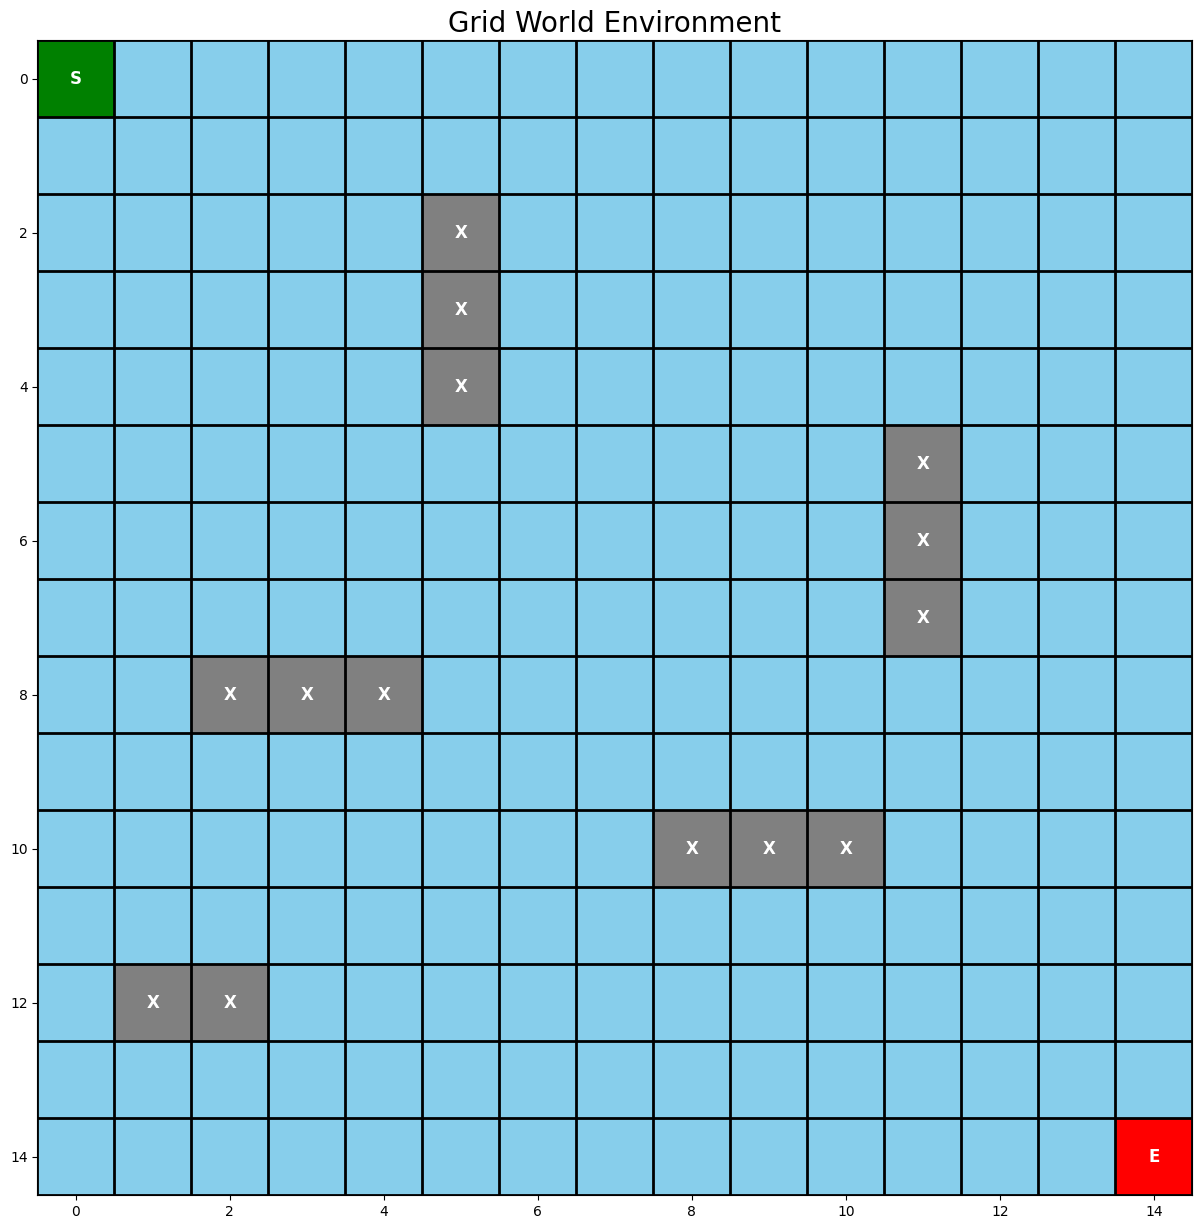

In [ ]:
fig, ax = plt.subplots(figsize=(GRID_SIZE, GRID_SIZE))

# Define colors for different cell types
colors = plt.cm.tab10 # Using a colormap for distinct colors

# Create a discrete colormap
cmap = plt.matplotlib.colors.ListedColormap(['skyblue', 'gray', 'green', 'red'])

# Plot the grid
im = ax.imshow(grid_display, cmap=cmap, origin='upper')

# Add grid lines
ax.set_xticks(np.arange(-.5, GRID_SIZE, 1), minor=True)
ax.set_yticks(np.arange(-.5, GRID_SIZE, 1), minor=True)
ax.grid(which="minor", color="black", linestyle='-', linewidth=2)
ax.tick_params(which="minor", size=0)

# Label cells
for i in range(GRID_SIZE):
    for j in range(GRID_SIZE):
        if (i, j) == start:
            ax.text(j, i, 'S', ha='center', va='center', color='white', fontsize=12, fontweight='bold')
        elif (i, j) == end:
            ax.text(j, i, 'E', ha='center', va='center', color='white', fontsize=12, fontweight='bold')
        elif grid[i, j] == 1:
            ax.text(j, i, 'X', ha='center', va='center', color='white', fontsize=12, fontweight='bold')

ax.set_title("Grid World Environment", fontsize=20)
plt.show()

# @title step_artifacts
num_fig = "1" # You can increment this for each new figure
step = 'EnvironmentSetup'  # Current step in the RL process
# Uncomment the following line to upload the figure to GCS if upload_plt_to_gcs is defined
# upload_plt_to_gcs(num_fig, step, fig)

## Definición del Proceso de Decisión de Markov (MDP)

Antes de aplicar la Iteración de Valores o la Iteración de Políticas, necesitamos formalizar el entorno como un MDP. Esto implica definir:

*   **Acciones (A):** Los movimientos que un agente puede realizar.
*   **Recompensas (R):** El valor que el agente recibe por entrar en un estado.
*   **Probabilidades de Transición (P):** La probabilidad de pasar de un estado a otro al tomar una acción.

In [ ]:
# 1. Acciones: Arriba, Abajo, Izquierda, Derecha
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)] # (row_change, col_change)
ACTION_NAMES = ['UP', 'DOWN', 'LEFT', 'RIGHT']

# 2. Recompensas
REWARD_NORMAL = -0.04  # Pequeño costo por cada paso para incentivar caminos cortos
REWARD_OBSTACLE = -1.0 # Gran penalización por chocar con un obstáculo
REWARD_GOAL = 1.0      # Gran recompensa por alcanzar el objetivo

# 3. Probabilidades de Transición (deterministas por simplicidad, 100% de éxito)
# P(s' | s, a) = 1 si s' es el resultado de tomar la acción 'a' desde 's'

# Función para obtener el siguiente estado
def get_next_state(current_state, action):
    r, c = current_state
    dr, dc = action
    new_r, new_c = r + dr, c + dc

    # Check boundaries
    if not (0 <= new_r < GRID_SIZE and 0 <= new_c < GRID_SIZE):
        return current_state # Stay in the same state if trying to move out of bounds

    # Check for obstacles
    if grid[new_r, new_c] == 1: # If it's an obstacle
        return current_state # Stay in the same state

    return (new_r, new_c)

# Función para obtener la recompensa de un estado
def get_reward(state):
    if state == end:
        return REWARD_GOAL
    elif grid[state] == 1: # This case should ideally not happen if get_next_state handles obstacles correctly
        return REWARD_OBSTACLE
    else:
        return REWARD_NORMAL

print("MDP components defined (Actions, Rewards, Transition Model).")

MDP components defined (Actions, Rewards, Transition Model).


## Algoritmo de Iteración de Valores

La Iteración de Valores es un algoritmo que calcula la función de valor óptima $V^*(s)$ para cada estado $s$. Utiliza la ecuación de Bellman para actualizar repetidamente los valores de los estados hasta que convergen. Una vez que tenemos la función de valor óptima, podemos derivar la política óptima.

La ecuación de Bellman para la Iteración de Valores es:

$V_{k+1}(s) = R(s) + \gamma \max_{a \in A} \sum_{s' \in S} P(s' | s, a) V_k(s')$

In [ ]:
# Inicialización
value_function = np.zeros((GRID_SIZE, GRID_SIZE)) # V(s) para cada estado
discount_factor = 0.9 # Gamma: Factor de descuento (importancia de futuras recompensas)
theta = 1e-5          # Umbral de convergencia

iterations = 0
MAX_ITERATIONS = 500
history_value_function = [] # To store value function at each iteration

print("Starting Value Iteration...")

while iterations < MAX_ITERATIONS:
    delta = 0 # Para medir el cambio máximo en V(s) en esta iteración
    new_value_function = np.copy(value_function)
    history_value_function.append(np.copy(value_function))

    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            state = (r, c)

            if state == end: # El estado objetivo tiene un valor fijo
                continue
            if grid[state] == 1: # Los obstáculos tienen un valor fijo (muy bajo o ignorado en la actualización)
                new_value_function[state] = REWARD_OBSTACLE # Opcional: penalizarlos fuertemente
                continue

            old_v = value_function[state]

            # Calcular el valor máximo Q(s, a) para todas las acciones
            q_values = []
            for action_idx, action in enumerate(ACTIONS):
                next_state = get_next_state(state, action)
                reward = get_reward(next_state) # Reward is received upon entering next_state
                q_value = reward + discount_factor * value_function[next_state]
                q_values.append(q_value)

            if q_values: # Ensure q_values is not empty
                new_v = max(q_values)
            else:
                new_v = old_v # No possible actions, value remains unchanged

            new_value_function[state] = new_v
            delta = max(delta, abs(old_v - new_v))

    value_function = new_value_function
    iterations += 1

    # Print progress for every N iterations
    if iterations % 50 == 0 or iterations == 1:
        print(f"Iteration {iterations}: Max change in value = {delta:.6f}")

    if delta < theta:
        print(f"Converged after {iterations} iterations. Max change in value = {delta:.6f}")
        break

print("Value Iteration finished.")

Starting Value Iteration...
Iteration 1: Max change in value = 1.000000
Converged after 29 iterations. Max change in value = 0.000000
Value Iteration finished.


## Visualización de la Función de Valor Final

Una vez que el algoritmo de Iteración de Valores ha convergido, podemos visualizar la función de valor final $V^*(s)$. Esto nos muestra qué tan 'valioso' es cada estado, es decir, qué tan buenas son las recompensas futuras esperadas desde ese estado si se sigue la política óptima.

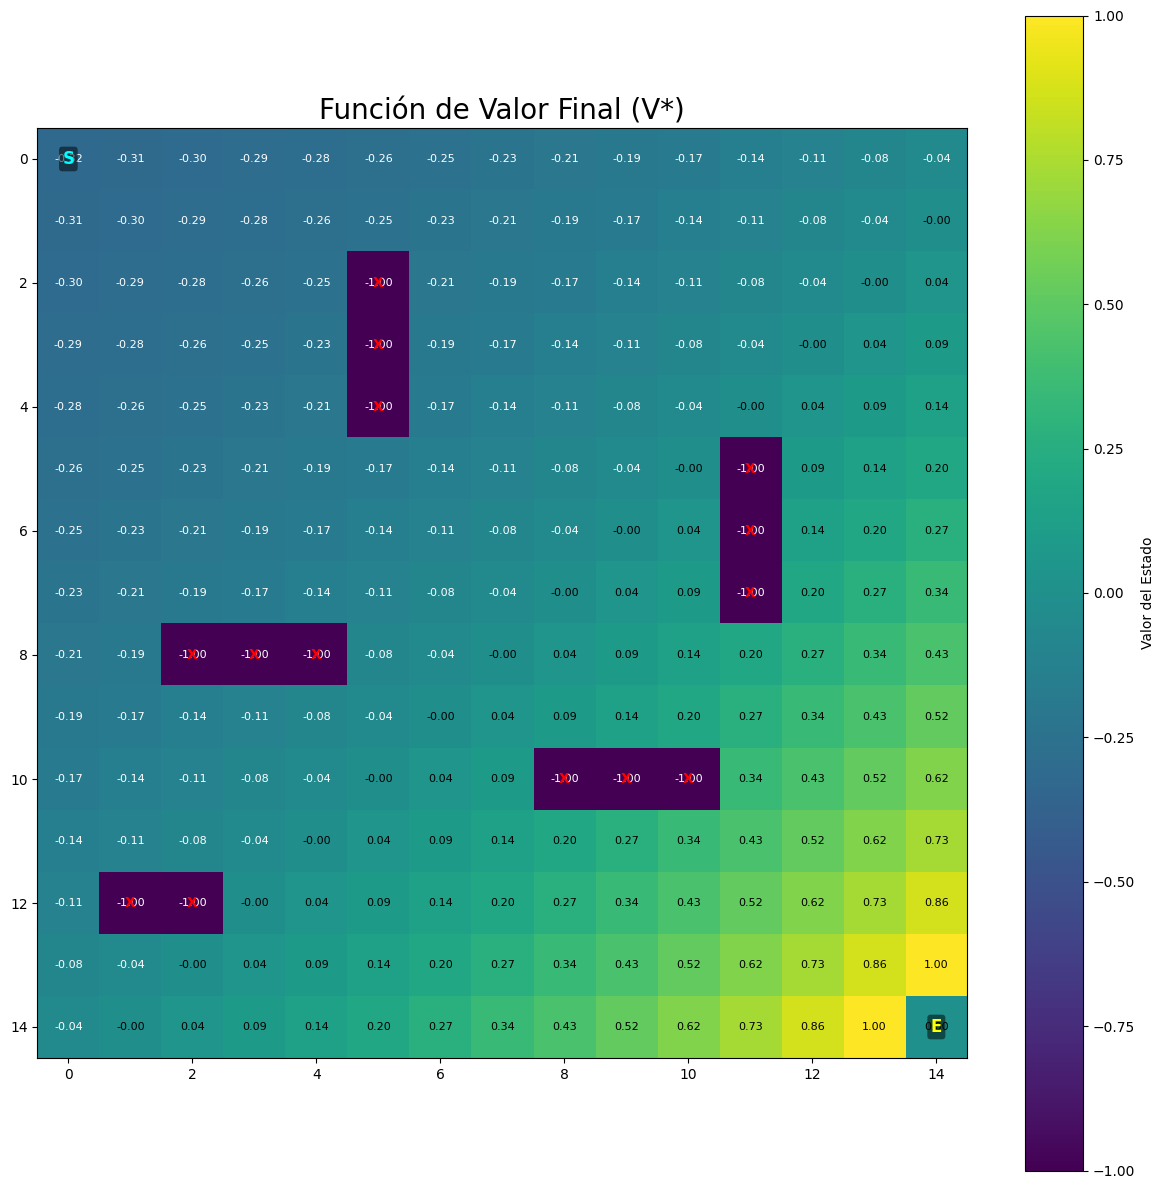

In [ ]:
fig, ax = plt.subplots(figsize=(GRID_SIZE, GRID_SIZE))

im = ax.imshow(value_function, cmap='viridis', origin='upper') # 'viridis' o 'hot' son buenas opciones

# Add values to cells
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        val = value_function[r, c]
        ax.text(c, r, f'{val:.2f}', ha='center', va='center', color='white' if val < np.mean(value_function) else 'black', fontsize=8)

# Add start and end markers
ax.text(start[1], start[0], 'S', ha='center', va='center', color='cyan', fontsize=12, fontweight='bold', bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', boxstyle='round,pad=0.2'))
ax.text(end[1], end[0], 'E', ha='center', va='center', color='yellow', fontsize=12, fontweight='bold', bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', boxstyle='round,pad=0.2'))

# Add obstacles markers
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        if grid[r, c] == 1:
            ax.text(c, r, 'X', ha='center', va='center', color='red', fontsize=10, fontweight='bold')

ax.set_title("Función de Valor Final (V*)", fontsize=20)
cbar = plt.colorbar(im)
cbar.set_label("Valor del Estado")
plt.show()

# @title step_artifacts
num_fig = "2" # You can increment this for each new figure
step = 'ValueIteration'  # Current step in the RL process
# upload_plt_to_gcs(num_fig, step, fig)

## Extracción de la Política Óptima

Una vez que tenemos la función de valor óptima $V^*(s)$, podemos determinar la política óptima $\pi^*(s)$ para cada estado. La política óptima es la acción que maximiza el valor esperado de la siguiente estado, considerando la función de valor $V^*(s)$.

$\pi^*(s) = \arg\max_{a \in A} \sum_{s' \in S} P(s' | s, a) V^*(s')$

In [ ]:
optimal_policy = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int) # Almacenará el índice de la acción óptima

print("Extracting optimal policy...")

for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        state = (r, c)

        if state == end or grid[state] == 1: # No policy needed for goal or obstacles
            optimal_policy[state] = -1 # Special value to indicate no action
            continue

        best_q_value = -np.inf
        best_action_idx = -1

        for action_idx, action in enumerate(ACTIONS):
            next_state = get_next_state(state, action)
            reward = get_reward(next_state) # Reward is received upon entering next_state
            q_value = reward + discount_factor * value_function[next_state]

            if q_value > best_q_value:
                best_q_value = q_value
                best_action_idx = action_idx

        optimal_policy[state] = best_action_idx

print("Optimal policy extracted.")

Extracting optimal policy...
Optimal policy extracted.


## Visualización de la Política Óptima y el Camino

Ahora, con la política óptima, podemos visualizar la mejor acción a tomar en cada estado y el camino que un agente seguiría desde el punto de inicio hasta el objetivo.

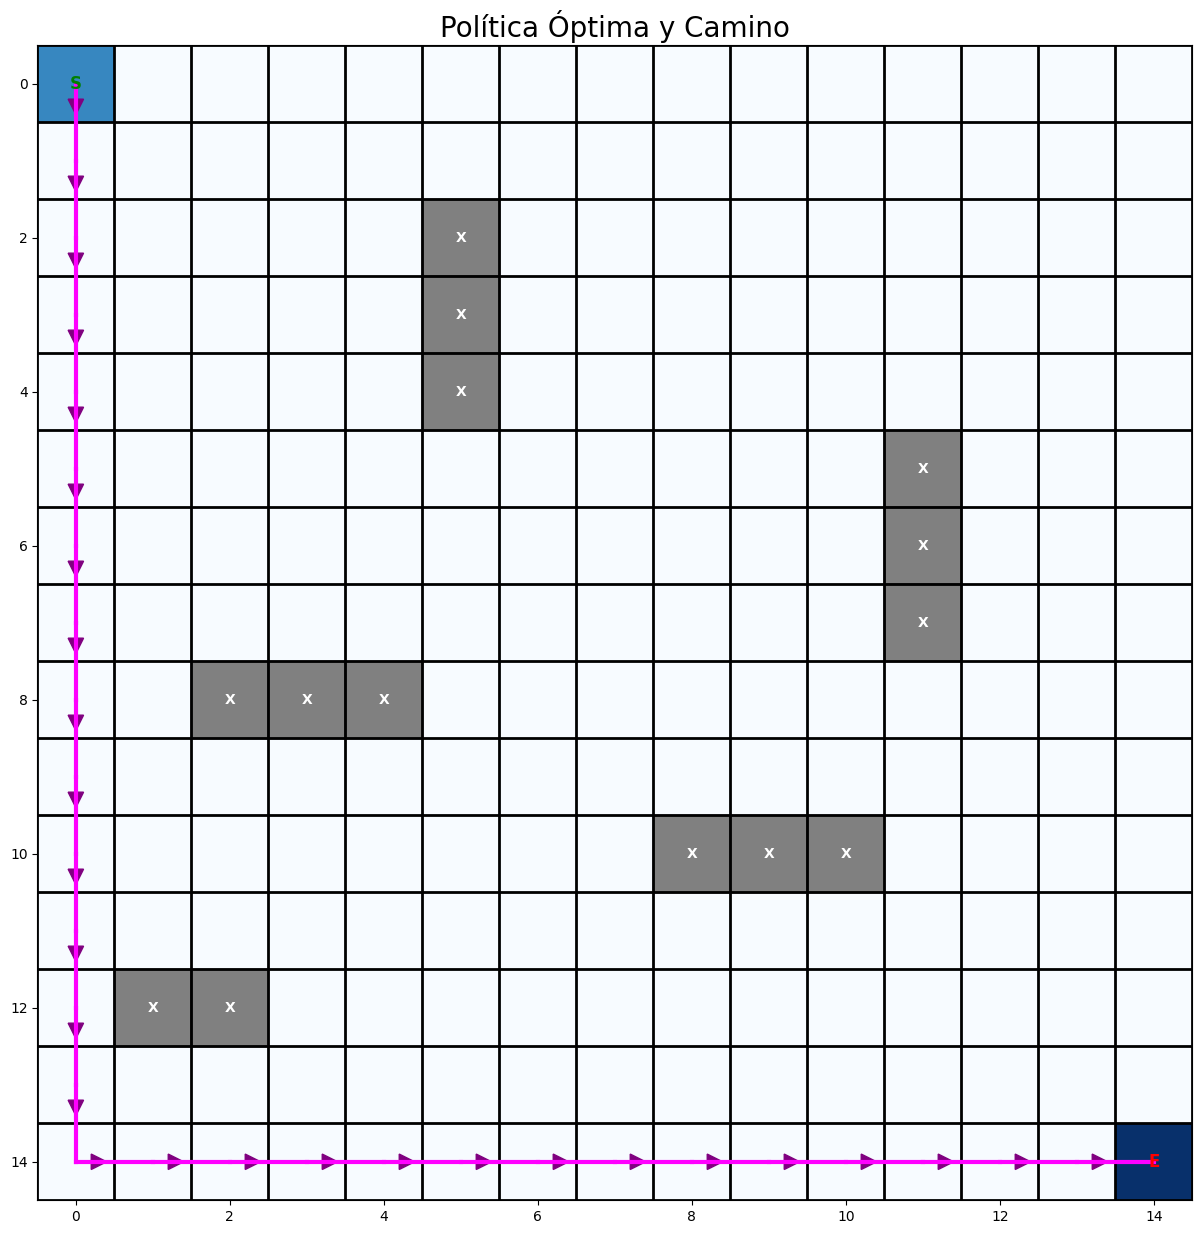

In [ ]:
fig, ax = plt.subplots(figsize=(GRID_SIZE, GRID_SIZE))

im = ax.imshow(grid_display, cmap='Blues', origin='upper') # Use 'Blues' to show the path clearly

# Add grid lines
ax.set_xticks(np.arange(-.5, GRID_SIZE, 1), minor=True)
ax.set_yticks(np.arange(-.5, GRID_SIZE, 1), minor=True)
ax.grid(which="minor", color="black", linestyle='-', linewidth=2)
ax.tick_params(which="minor", size=0)

# Mark start and end
ax.text(start[1], start[0], 'S', ha='center', va='center', color='green', fontsize=12, fontweight='bold')
ax.text(end[1], end[0], 'E', ha='center', va='center', color='red', fontsize=12, fontweight='bold')

# Plot obstacles
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        if grid[r, c] == 1:
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor='gray', edgecolor='black', linewidth=1))
            ax.text(c, r, 'X', ha='center', va='center', color='white', fontsize=10, fontweight='bold')

# Plot policy arrows and optimal path
current_state = start
path = [current_state]

while current_state != end:
    if optimal_policy[current_state] == -1: # Should not happen if path to end exists
        print(f"Stuck or no path from {current_state} to end.")
        break

    action_idx = optimal_policy[current_state]
    action = ACTIONS[action_idx]

    # Draw arrow for policy
    arrow_color = 'purple'
    ax.arrow(current_state[1], current_state[0], action[1] * 0.4, action[0] * 0.4,
             head_width=0.2, head_length=0.2, fc=arrow_color, ec=arrow_color,
             length_includes_head=True)

    next_state = get_next_state(current_state, action)
    if next_state == current_state: # Agent couldn't move (hit boundary/obstacle)
        print(f"Agent got stuck at {current_state} while trying to move with action {ACTION_NAMES[action_idx]}")
        break

    current_state = next_state
    path.append(current_state)

# Draw the optimal path (thicker line)
for i in range(len(path) - 1):
    r1, c1 = path[i]
    r2, c2 = path[i+1]
    ax.plot([c1, c2], [r1, r2], color='magenta', linewidth=3)

ax.set_title("Política Óptima y Camino", fontsize=20)
plt.show()

# @title step_artifacts
num_fig = "3" # You can increment this for each new figure
step = 'OptimalPathVisualization'  # Current step in the RL process
# upload_plt_to_gcs(num_fig, step, fig)

## Algoritmo de Iteración de Políticas

La Iteración de Políticas es una alternativa a la Iteración de Valores para encontrar la política óptima. Consiste en dos pasos iterativos:

1.  **Evaluación de Políticas (Policy Evaluation):** Dado una política $\pi$, se calcula la función de valor $V_\pi(s)$ para cada estado $s$. Esto se hace resolviendo un sistema de ecuaciones o mediante actualizaciones iterativas (similar a la Iteración de Valores, pero sin el `max` sobre las acciones).
    $V_{k+1}(s) = R(s) + \gamma \sum_{s' \in S} P(s' | s, \pi(s)) V_k(s')$

2.  **Mejora de Políticas (Policy Improvement):** Dada la función de valor $V_\pi(s)$, se deriva una nueva y mejor política $\pi'(s)$ greedy con respecto a $V_\pi(s)$.
    $\pi'(s) = \arg\max_{a \in A} \sum_{s' \in S} P(s' | s, a) V_\pi(s')$

Estos dos pasos se repiten hasta que la política ya no mejora (es decir, converge).

In [ ]:
# Inicialización para Iteración de Políticas
policy = np.random.randint(0, len(ACTIONS), size=(GRID_SIZE, GRID_SIZE)) # Política aleatoria inicial
value_function_pi = np.zeros((GRID_SIZE, GRID_SIZE)) # V(s) para cada estado

discount_factor_pi = 0.9
theta_pi = 1e-5

policy_iteration_count = 0
MAX_POLICY_ITERATIONS = 50

print("Starting Policy Iteration...")

while policy_iteration_count < MAX_POLICY_ITERATIONS:
    policy_stable = True
    policy_iteration_count += 1

    # --- 1. Policy Evaluation ---
    # Se calcula V_pi para la política actual
    evaluation_iterations = 0
    MAX_EVALUATION_ITERATIONS = 1000 # Max iterations for policy evaluation

    while evaluation_iterations < MAX_EVALUATION_ITERATIONS:
        delta_eval = 0
        new_value_function_pi = np.copy(value_function_pi)

        for r in range(GRID_SIZE):
            for c in range(GRID_SIZE):
                state = (r, c)

                if state == end:
                    continue
                if grid[state] == 1:
                    new_value_function_pi[state] = REWARD_OBSTACLE # Keep obstacle value fixed
                    continue

                old_v = value_function_pi[state]

                # Acción según la política actual
                action_idx = policy[state]
                action = ACTIONS[action_idx]

                next_state = get_next_state(state, action)
                reward = get_reward(next_state)

                new_v = reward + discount_factor_pi * value_function_pi[next_state]
                new_value_function_pi[state] = new_v
                delta_eval = max(delta_eval, abs(old_v - new_v))

        value_function_pi = new_value_function_pi
        evaluation_iterations += 1

        if delta_eval < theta_pi:
            break

    # --- 2. Policy Improvement ---
    # Se mejora la política basándose en V_pi
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            state = (r, c)

            if state == end or grid[state] == 1:
                continue

            old_action_idx = policy[state]

            best_q_value = -np.inf
            best_action_idx = -1

            for action_idx, action in enumerate(ACTIONS):
                next_state = get_next_state(state, action)
                reward = get_reward(next_state)
                q_value = reward + discount_factor_pi * value_function_pi[next_state]

                if q_value > best_q_value:
                    best_q_value = q_value
                    best_action_idx = action_idx

            policy[state] = best_action_idx

            if old_action_idx != best_action_idx:
                policy_stable = False

    print(f"Policy Iteration {policy_iteration_count}: Policy stable = {policy_stable}")

    if policy_stable:
        print(f"Policy Iteration converged after {policy_iteration_count} iterations.")
        break

print("Policy Iteration finished.")

Starting Policy Iteration...
Policy Iteration 1: Policy stable = False
Policy Iteration 2: Policy stable = False
Policy Iteration 3: Policy stable = False
Policy Iteration 4: Policy stable = False
Policy Iteration 5: Policy stable = False
Policy Iteration 6: Policy stable = False
Policy Iteration 7: Policy stable = False
Policy Iteration 8: Policy stable = False
Policy Iteration 9: Policy stable = False
Policy Iteration 10: Policy stable = False
Policy Iteration 11: Policy stable = False
Policy Iteration 12: Policy stable = False
Policy Iteration 13: Policy stable = False
Policy Iteration 14: Policy stable = False
Policy Iteration 15: Policy stable = False
Policy Iteration 16: Policy stable = False
Policy Iteration 17: Policy stable = False
Policy Iteration 18: Policy stable = False
Policy Iteration 19: Policy stable = False
Policy Iteration 20: Policy stable = False
Policy Iteration 21: Policy stable = False
Policy Iteration 22: Policy stable = False
Policy Iteration 23: Policy stable

## Visualización de la Función de Valor Final (Iteración de Políticas)

Vamos a visualizar la función de valor $V_\pi(s)$ obtenida después de la convergencia de la Iteración de Políticas.

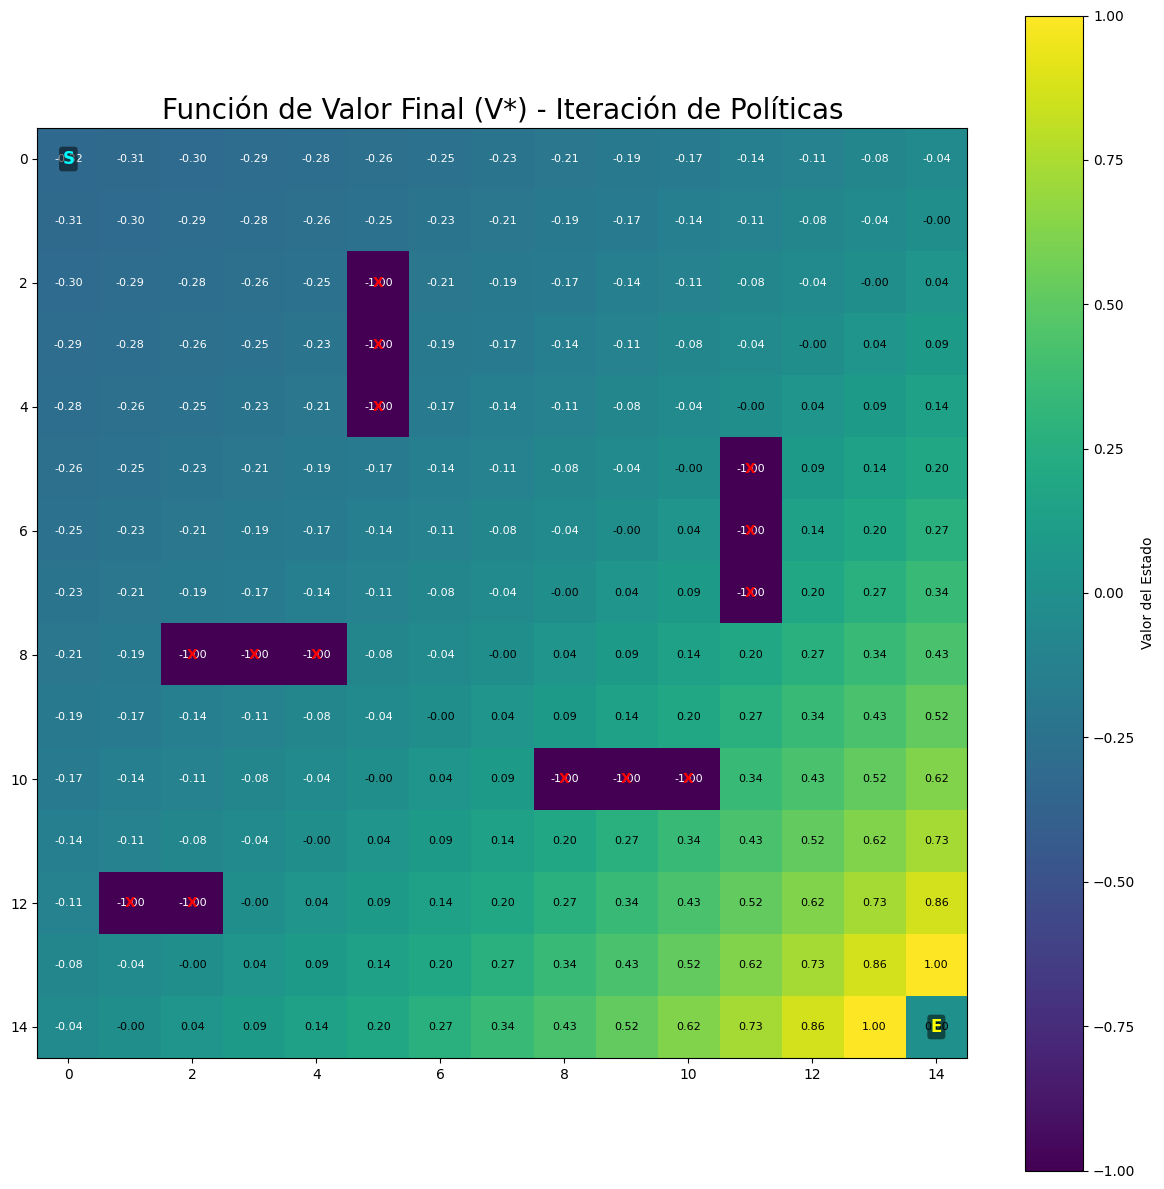

In [ ]:
fig, ax = plt.subplots(figsize=(GRID_SIZE, GRID_SIZE))

im = ax.imshow(value_function_pi, cmap='viridis', origin='upper') # 'viridis' o 'hot' son buenas opciones

# Add values to cells
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        val = value_function_pi[r, c]
        ax.text(c, r, f'{val:.2f}', ha='center', va='center', color='white' if val < np.mean(value_function_pi) else 'black', fontsize=8)

# Add start and end markers
ax.text(start[1], start[0], 'S', ha='center', va='center', color='cyan', fontsize=12, fontweight='bold', bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', boxstyle='round,pad=0.2'))
ax.text(end[1], end[0], 'E', ha='center', va='center', color='yellow', fontsize=12, fontweight='bold', bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', boxstyle='round,pad=0.2'))

# Add obstacles markers
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        if grid[r, c] == 1:
            ax.text(c, r, 'X', ha='center', va='center', color='red', fontsize=10, fontweight='bold')

ax.set_title("Función de Valor Final (V*) - Iteración de Políticas", fontsize=20)
cbar = plt.colorbar(im)
cbar.set_label("Valor del Estado")
plt.show()

# @title step_artifacts
num_fig = "4" # You can increment this for each new figure
step = 'PolicyIterationValueFunction'  # Current step in the RL process
# upload_plt_to_gcs(num_fig, step, fig)

## Visualización de la Política Óptima y el Camino (Iteración de Políticas)

Finalmente, visualicemos la política óptima y el camino que se seguiría desde el inicio hasta el objetivo, según la Iteración de Políticas.

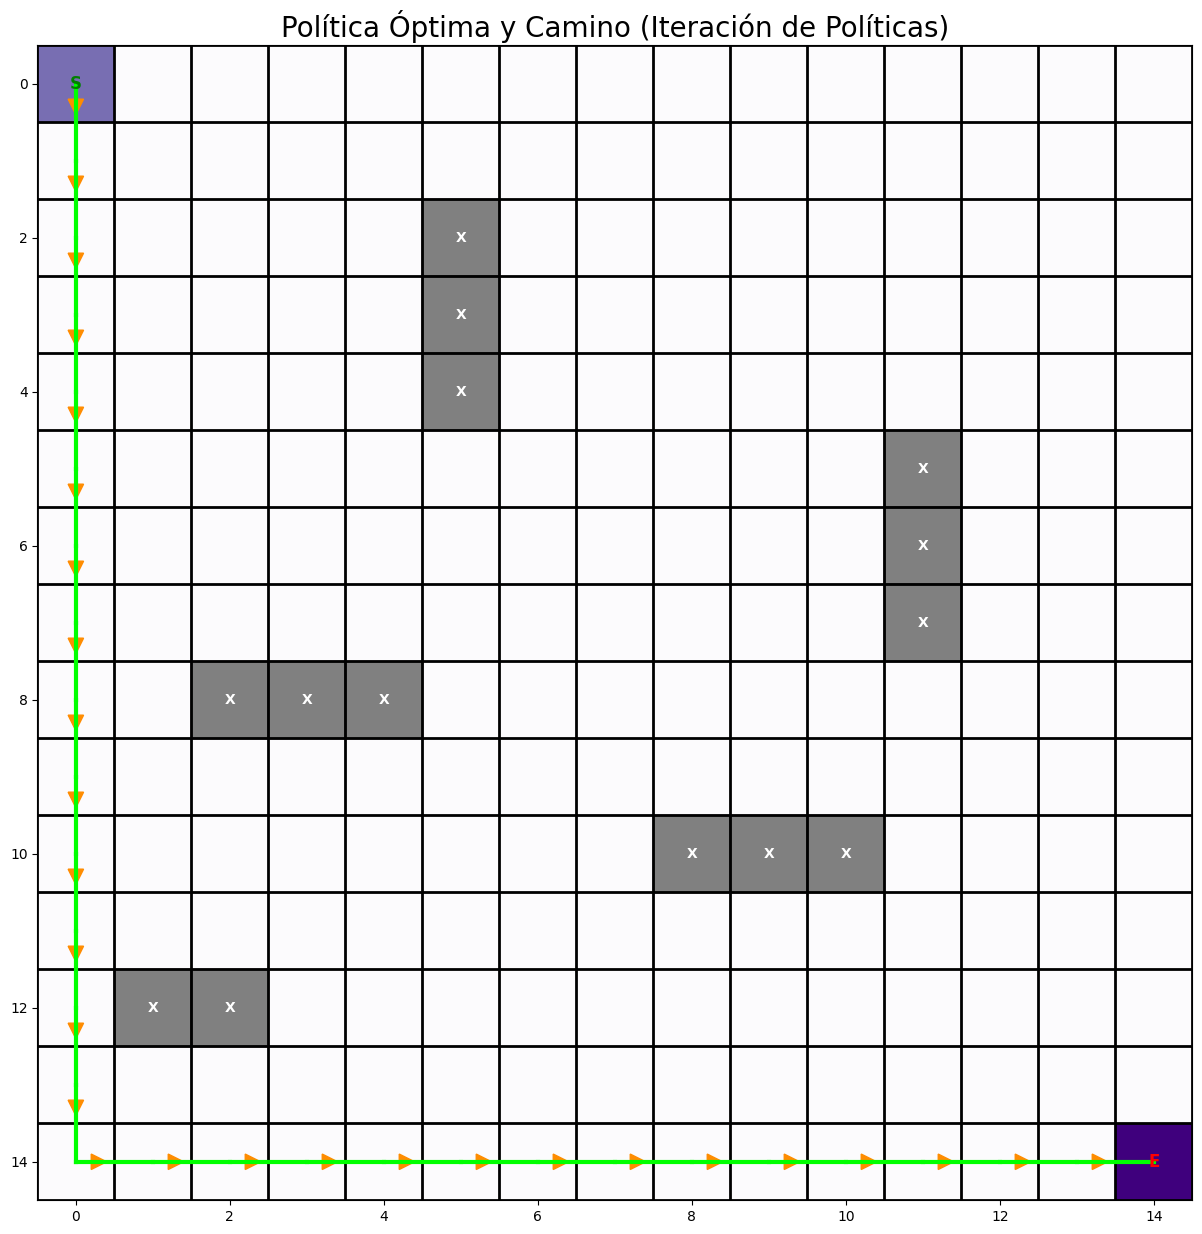

In [ ]:
fig, ax = plt.subplots(figsize=(GRID_SIZE, GRID_SIZE))

im = ax.imshow(grid_display, cmap='Purples', origin='upper') # Use 'Purples' to distinguish from Value Iteration path

# Add grid lines
ax.set_xticks(np.arange(-.5, GRID_SIZE, 1), minor=True)
ax.set_yticks(np.arange(-.5, GRID_SIZE, 1), minor=True)
ax.grid(which="minor", color="black", linestyle='-', linewidth=2)
ax.tick_params(which="minor", size=0)

# Mark start and end
ax.text(start[1], start[0], 'S', ha='center', va='center', color='green', fontsize=12, fontweight='bold')
ax.text(end[1], end[0], 'E', ha='center', va='center', color='red', fontsize=12, fontweight='bold')

# Plot obstacles
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        if grid[r, c] == 1:
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor='gray', edgecolor='black', linewidth=1))
            ax.text(c, r, 'X', ha='center', va='center', color='white', fontsize=10, fontweight='bold')

# Plot policy arrows and optimal path
current_state = start
path_pi = [current_state]

while current_state != end:
    if policy[current_state] == -1: # Should not happen if path to end exists
        print(f"Stuck or no path from {current_state} to end for Policy Iteration.")
        break

    action_idx = policy[current_state]
    action = ACTIONS[action_idx]

    # Draw arrow for policy
    arrow_color = 'darkorange'
    ax.arrow(current_state[1], current_state[0], action[1] * 0.4, action[0] * 0.4,
             head_width=0.2, head_length=0.2, fc=arrow_color, ec=arrow_color,
             length_includes_head=True)

    next_state = get_next_state(current_state, action)
    if next_state == current_state: # Agent couldn't move (hit boundary/obstacle)
        print(f"Agent got stuck at {current_state} with Policy Iteration while trying to move with action {ACTION_NAMES[action_idx]}")
        break

    current_state = next_state
    path_pi.append(current_state)

# Draw the optimal path (thicker line)
for i in range(len(path_pi) - 1):
    r1, c1 = path_pi[i]
    r2, c2 = path_pi[i+1]
    ax.plot([c1, c2], [r1, r2], color='lime', linewidth=3)

ax.set_title("Política Óptima y Camino (Iteración de Políticas)", fontsize=20)
plt.show()

# @title step_artifacts
num_fig = "5" # You can increment this for each new figure
step = 'PolicyIterationPathVisualization'  # Current step in the RL process
# upload_plt_to_gcs(num_fig, step, fig)

## Algoritmo de Q-Learning

Q-learning es un algoritmo de aprendizaje por refuerzo *sin modelo* (model-free) que aprende una política óptima. A diferencia de la Iteración de Valores o la Iteración de Políticas, no necesita un modelo del entorno (probabilidades de transición y función de recompensa). En su lugar, aprende directamente la función de valor de acción $Q(s, a)$, que representa la recompensa esperada de tomar la acción $a$ en el estado $s$ y luego seguir la política óptima.

La ecuación de actualización de Q-learning es:

$Q(s, a) \leftarrow Q(s, a) + \alpha [R_{t+1} + \gamma \max_{a'} Q(s', a') - Q(s, a)]$

Donde:
*   $Q(s, a)$: Valor Q para el estado $s$ y la acción $a$.
*   $\alpha$: Tasa de aprendizaje (learning rate), que determina cuánto se actualiza el valor Q en cada paso.
*   $R_{t+1}$: Recompensa recibida después de tomar la acción $a$ desde el estado $s$.
*   $\gamma$: Factor de descuento, que pondera la importancia de las recompensas futuras.
*   $s'$: El nuevo estado al que se llega después de tomar la acción $a$ desde $s$.
*   $\max_{a'} Q(s', a')$: El valor Q máximo posible en el siguiente estado $s'$.

In [19]:
# Inicialización para Q-learning
# Q-tabla: Filas son estados (r * GRID_SIZE + c), columnas son acciones
num_states = GRID_SIZE * GRID_SIZE
num_actions = len(ACTIONS)
Q_table = np.zeros((num_states, num_actions))

# Parámetros de Q-learning
learning_rate = 0.8  # Alpha
discount_factor_ql = 0.95 # Gamma
epsilon = 0.1        # Epsilon para la política epsilon-greedy
num_episodes = 1000  # Número de episodios de entrenamiento

print("Q-learning parameters initialized.")

Q-learning parameters initialized.


In [20]:
print("Starting Q-learning training...")

# Función para mapear un estado (r, c) a un índice único
def state_to_index(state):
    r, c = state
    return r * GRID_SIZE + c

# Función para mapear un índice a un estado (r, c)
def index_to_state(index):
    r = index // GRID_SIZE
    c = index % GRID_SIZE
    return (r, c)

for episode in range(num_episodes):
    current_state = start
    current_state_idx = state_to_index(current_state)
    done = False

    while not done:
        # Política epsilon-greedy para seleccionar la acción
        if random.uniform(0, 1) < epsilon:
            action_idx = random.randint(0, num_actions - 1) # Exploración
        else:
            action_idx = np.argmax(Q_table[current_state_idx, :]) # Explotación

        action = ACTIONS[action_idx]

        # Obtener el siguiente estado y la recompensa
        next_state = get_next_state(current_state, action)
        reward = get_reward(next_state)

        # Si el siguiente estado es el objetivo, el episodio termina
        if next_state == end:
            done = True
        # Si el siguiente estado es un obstáculo (no debería suceder si get_next_state lo maneja)
        # o si el agente se queda atascado en el mismo estado debido a un límite/obstáculo
        elif grid[next_state] == 1 or next_state == current_state:
            # Penalizar fuertemente si se intenta ir a un obstáculo o si no se mueve
            if next_state == current_state and grid[current_state] != 1: # Only penalize if it's not already an obstacle
                 reward = REWARD_OBSTACLE # Penalize for hitting boundary or being stuck
            done = True # Consider episode done if stuck or hit obstacle

        next_state_idx = state_to_index(next_state)

        # Actualizar el valor Q
        old_q_value = Q_table[current_state_idx, action_idx]
        max_future_q = np.max(Q_table[next_state_idx, :])

        new_q_value = old_q_value + learning_rate * (reward + discount_factor_ql * max_future_q - old_q_value)
        Q_table[current_state_idx, action_idx] = new_q_value

        current_state = next_state
        current_state_idx = next_state_idx

        if current_state == end:
            done = True

    if episode % 100 == 0:
        print(f"Episode {episode}/{num_episodes} finished.")

print("Q-learning training finished.")

Starting Q-learning training...
Episode 0/1000 finished.
Episode 100/1000 finished.
Episode 200/1000 finished.
Episode 300/1000 finished.
Episode 400/1000 finished.
Episode 500/1000 finished.
Episode 600/1000 finished.
Episode 700/1000 finished.
Episode 800/1000 finished.
Episode 900/1000 finished.
Q-learning training finished.


## Extracción y Visualización de la Política Óptima de Q-Learning

Una vez que la tabla Q ha sido entrenada, podemos derivar la política óptima tomando la acción con el valor Q más alto para cada estado. Luego, visualizaremos el camino que el agente seguiría desde el inicio hasta el objetivo utilizando esta política.

Optimal policy from Q-table extracted.


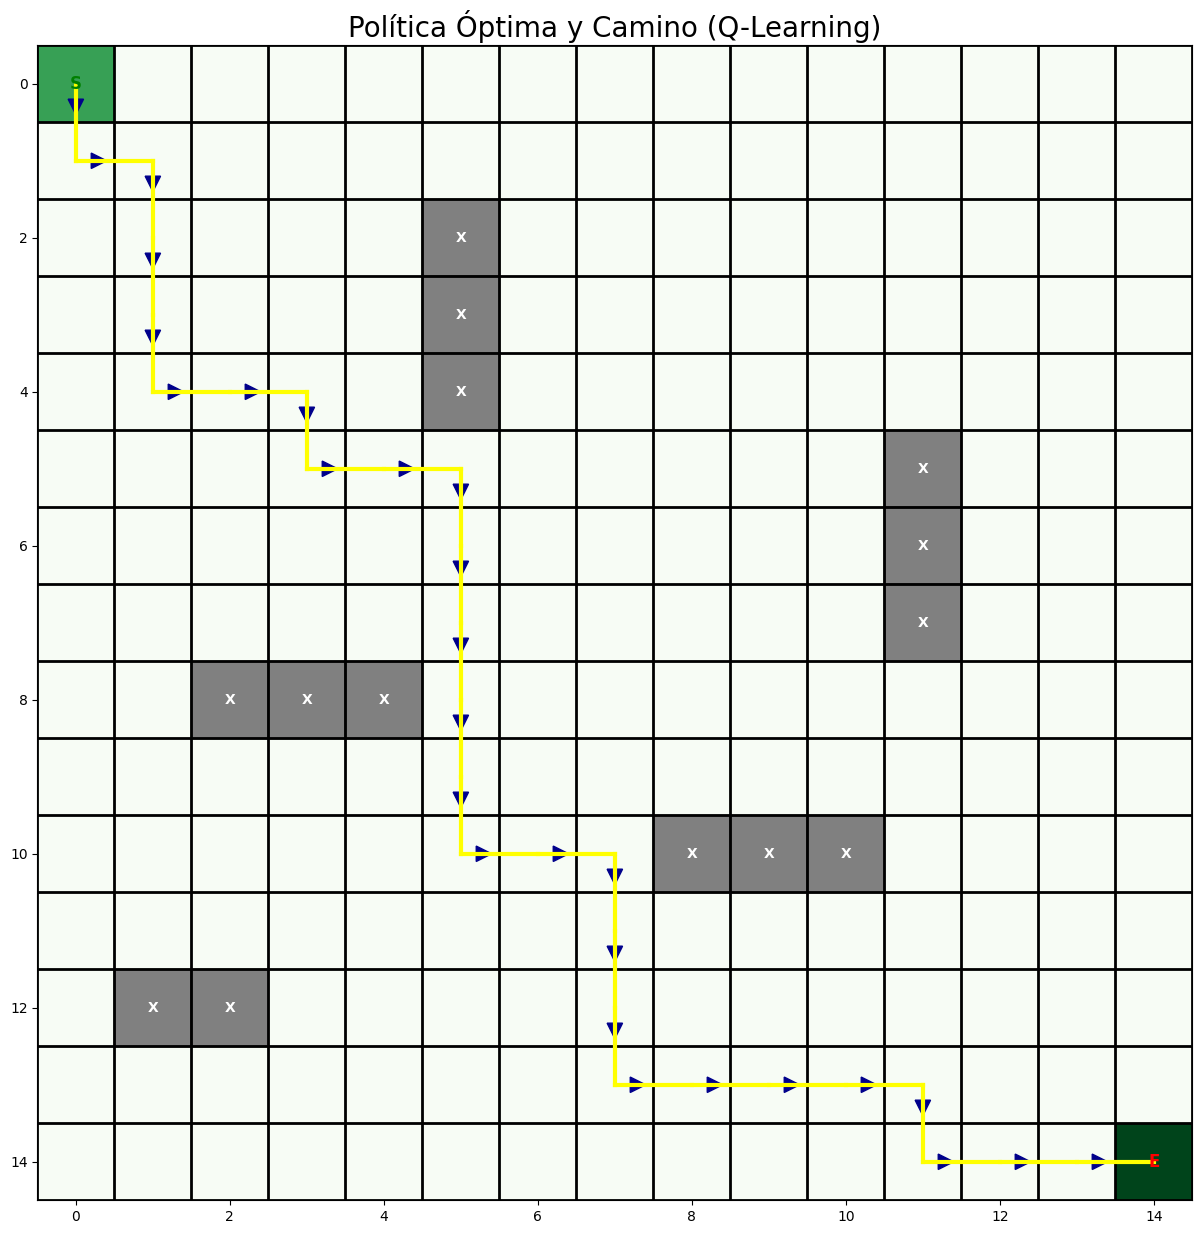

In [21]:
# Extraer la política óptima de la tabla Q
optimal_policy_ql = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)

for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        state = (r, c)
        state_idx = state_to_index(state)

        if state == end or grid[state] == 1:
            optimal_policy_ql[state] = -1 # No policy for goal or obstacles
        else:
            optimal_policy_ql[state] = np.argmax(Q_table[state_idx, :])

print("Optimal policy from Q-table extracted.")

# Visualizar el camino óptimo de Q-learning
fig, ax = plt.subplots(figsize=(GRID_SIZE, GRID_SIZE))

im = ax.imshow(grid_display, cmap='Greens', origin='upper') # Usar 'Greens' para el camino de Q-learning

# Add grid lines
ax.set_xticks(np.arange(-.5, GRID_SIZE, 1), minor=True)
ax.set_yticks(np.arange(-.5, GRID_SIZE, 1), minor=True)
ax.grid(which="minor", color="black", linestyle='-', linewidth=2)
ax.tick_params(which="minor", size=0)

# Mark start and end
ax.text(start[1], start[0], 'S', ha='center', va='center', color='green', fontsize=12, fontweight='bold')
ax.text(end[1], end[0], 'E', ha='center', va='center', color='red', fontsize=12, fontweight='bold')

# Plot obstacles
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        if grid[r, c] == 1:
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor='gray', edgecolor='black', linewidth=1))
            ax.text(c, r, 'X', ha='center', va='center', color='white', fontsize=10, fontweight='bold')

# Plot policy arrows and optimal path
current_state = start
path_ql = [current_state]

while current_state != end:
    if optimal_policy_ql[current_state] == -1:
        print(f"Stuck or no path from {current_state} to end for Q-learning.")
        break

    action_idx = optimal_policy_ql[current_state]
    action = ACTIONS[action_idx]

    # Draw arrow for policy
    arrow_color = 'darkblue'
    ax.arrow(current_state[1], current_state[0], action[1] * 0.4, action[0] * 0.4,
             head_width=0.2, head_length=0.2, fc=arrow_color, ec=arrow_color,
             length_includes_head=True)

    next_state = get_next_state(current_state, action)
    if next_state == current_state:
        print(f"Agent got stuck at {current_state} with Q-learning while trying to move with action {ACTION_NAMES[action_idx]}")
        break

    current_state = next_state
    path_ql.append(current_state)

# Draw the optimal path (thicker line)
for i in range(len(path_ql) - 1):
    r1, c1 = path_ql[i]
    r2, c2 = path_ql[i+1]
    ax.plot([c1, c2], [r1, r2], color='yellow', linewidth=3)

ax.set_title("Política Óptima y Camino (Q-Learning)", fontsize=20)
plt.show()

# @title step_artifacts
num_fig = "6" # Increment for Q-learning path
step = 'QLearningPathVisualization'  # Current step in the RL process
# upload_plt_to_gcs(num_fig, step, fig)


## Comparación de Resultados

Ahora podemos comparar los caminos y las políticas obtenidas por los tres métodos:

1.  **Iteración de Valores:** Algoritmo *model-based* que converge a la función de valor óptima y de ahí se deriva la política.
2.  **Iteración de Políticas:** Algoritmo *model-based* que alterna entre la evaluación y mejora de políticas hasta la convergencia.
3.  **Q-Learning:** Algoritmo *model-free* que aprende directamente la función de valor de acción $Q(s,a)$ a través de la experiencia.

En este entorno determinista y pequeño, se espera que los tres algoritmos encuentren caminos óptimos muy similares, si no idénticos, desde el inicio hasta el objetivo. Las principales diferencias radican en cómo llegan a esa solución (model-based vs. model-free, iteración de valores vs. iteración de políticas).

Observaciones:
*   **Caminos:** Compara la longitud y la ruta visual de `path` (Iteración de Valores), `path_pi` (Iteración de Políticas) y `path_ql` (Q-Learning).
*   **Convergencia:** La Iteración de Valores y la Iteración de Políticas convergen a la solución exacta dada las recompensas y transiciones. Q-Learning es un algoritmo de aproximación que converge asintóticamente a la solución óptima, y su rendimiento puede depender de los hiperparámetros (tasa de aprendizaje, factor de descuento, epsilon) y el número de episodios.